# EDA - Dataset do Alfabeto em Libras

Dataset: [LIBRAS - Hand Landmarks Dataset](https://www.kaggle.com/datasets/williansoliveira/libras) (Kaggle, williansoliveira).

Ao baixar, o dataset veio como **imagens 64x64 PNG** organizadas em dataset/raw_alphabet/{train,test}/{letra}/.png`,
não como CSV de landmarks já extraídos (diferente do que a descrição do dataset sugeria). 21 classes (letras estáticas;
H, J, K, X e Z ficam de fora porque em Libras envolvem movimento, impossível representar numa imagem única).

> Execute este notebook a partir da raiz do projeto (`pose-detector/`).

In [1]:
import os
import sys

# garante que a raiz do projeto esteja no path, mesmo se o Jupyter for aberto a partir de notebooks/
if os.path.basename(os.getcwd()) == 'notebooks':
    os.chdir('..')
sys.path.insert(0, os.getcwd())

import hashlib
import time
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image
from sklearn.neighbors import NearestNeighbors

sns.set_theme(style="whitegrid")

BASE = Path("dataset/raw_alphabet")
CLASSES = sorted(p.name for p in (BASE / "train").iterdir())
CLASSES

['A',
 'B',
 'C',
 'D',
 'E',
 'F',
 'G',
 'I',
 'L',
 'M',
 'N',
 'O',
 'P',
 'Q',
 'R',
 'S',
 'T',
 'U',
 'V',
 'W',
 'Y']

## Data Understanding (CRISP-DM)

## Visão geral do dataset

In [2]:
contagem = pd.DataFrame([
    {
        "letra": cls,
        "n_train": len(list((BASE / "train" / cls).glob("*.png"))),
        "n_test": len(list((BASE / "test" / cls).glob("*.png"))),
    }
    for cls in CLASSES
])
contagem["total"] = contagem["n_train"] + contagem["n_test"]
contagem.set_index("letra")

,n_train,n_test,total
letra,,,
A,1686,564,2250
B,1662,556,2218
C,1686,571,2257
D,1650,550,2200
E,1670,574,2244
F,1647,450,2097
G,1650,550,2200
I,1650,550,2200
L,1650,550,2200


In [3]:
print("Total de imagens - train:", contagem["n_train"].sum())
print("Total de imagens - test:", contagem["n_test"].sum())
print("Classes:", len(CLASSES))

Total de imagens - train: 34714
Total de imagens - test: 11515
Classes: 21


## Balanceamento de classes

treino - min/max/std por letra: 1614 1686 14.6
teste - min/max/std por letra: 450 574 23.7


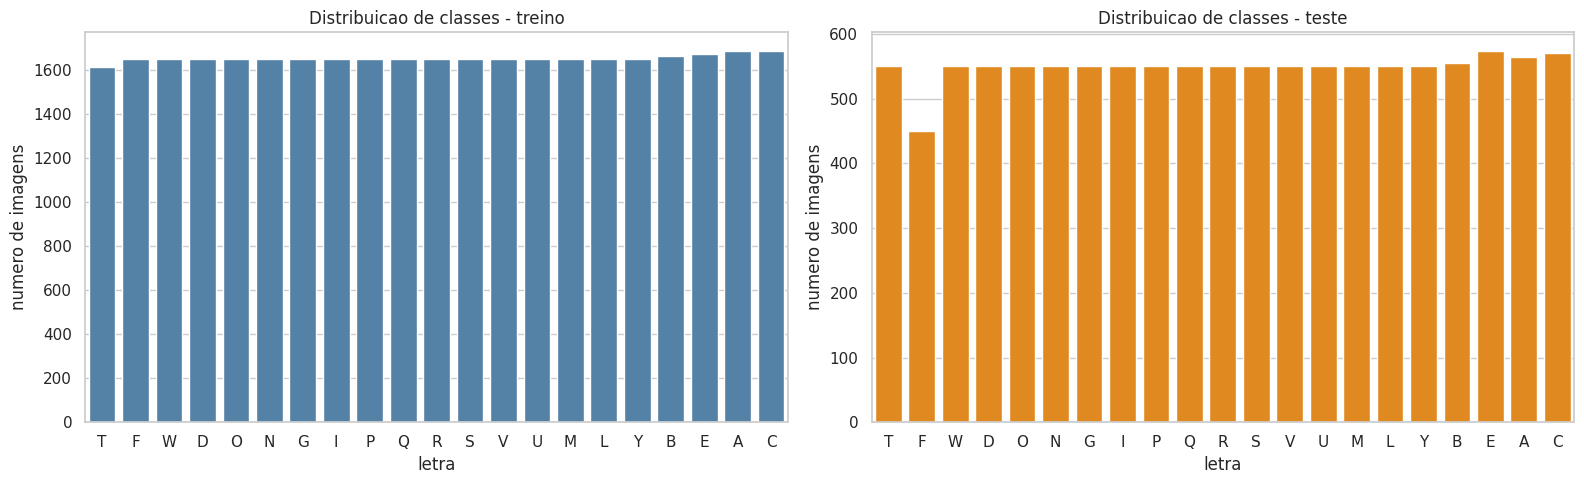

In [4]:
print("treino - min/max/std por letra:", contagem["n_train"].min(), contagem["n_train"].max(), round(contagem["n_train"].std(), 1))
print("teste - min/max/std por letra:", contagem["n_test"].min(), contagem["n_test"].max(), round(contagem["n_test"].std(), 1))

fig, axes = plt.subplots(1, 2, figsize=(16, 5))
ordem = contagem.sort_values("n_train")["letra"]

sns.barplot(data=contagem.sort_values("n_train"), x="letra", y="n_train", order=ordem, ax=axes[0], color="steelblue")
axes[0].set_title("Distribuicao de classes - treino")
axes[0].set_ylabel("numero de imagens")

sns.barplot(data=contagem.sort_values("n_train"), x="letra", y="n_test", order=ordem, ax=axes[1], color="darkorange")
axes[1].set_title("Distribuicao de classes - teste")
axes[1].set_ylabel("numero de imagens")

plt.tight_layout()
plt.savefig("notebooks/class_distribution_alfabeto.png", dpi=120)
plt.show()

## Visualizar amostras

Uma imagem de exemplo de cada letra (primeira imagem do treino), so pra checar visualmente se o dataset
e consistente (mao centralizada, fundo parecido, letra condizente com a pasta).

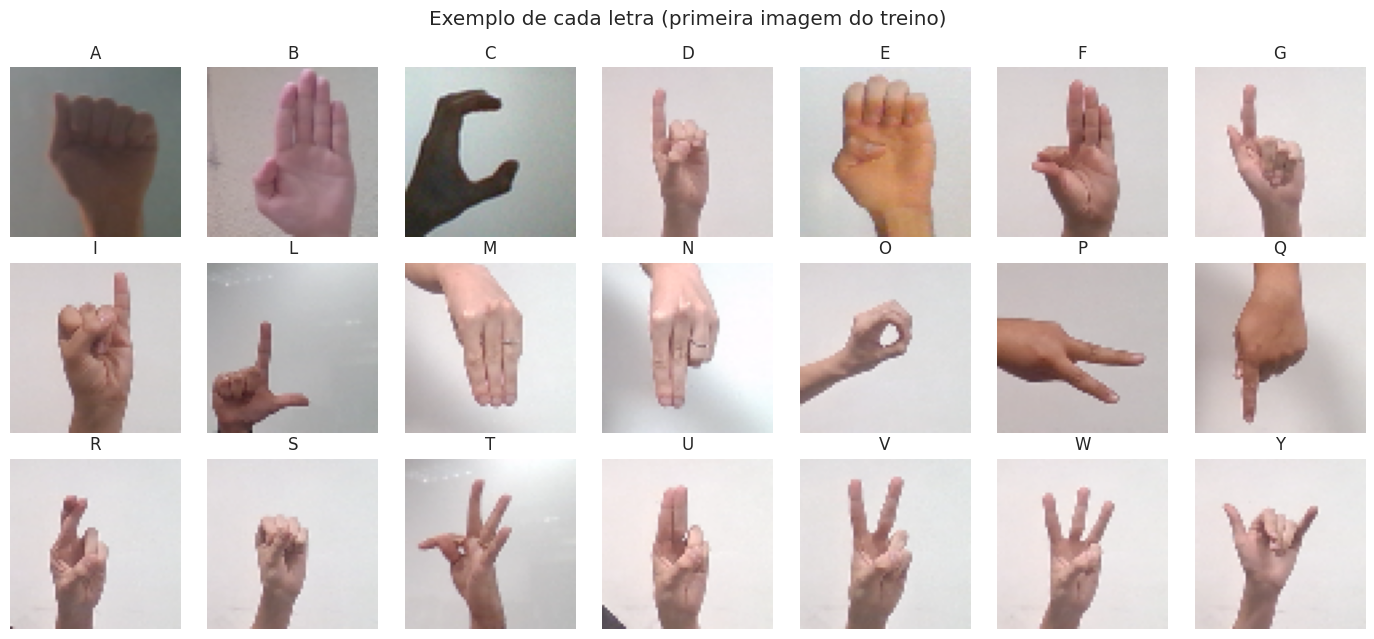

In [5]:
fig, axes = plt.subplots(3, 7, figsize=(14, 6.5))
for ax, cls in zip(axes.ravel(), CLASSES):
    exemplo = sorted((BASE / "train" / cls).glob("*.png"))[0]
    ax.imshow(Image.open(exemplo))
    ax.set_title(cls, fontsize=12)
    ax.axis("off")

plt.suptitle("Exemplo de cada letra (primeira imagem do treino)")
plt.tight_layout()
plt.savefig("notebooks/amostras_alfabeto.png", dpi=120)
plt.show()

## Verificação de leakage entre train e test

Esse dataset já vem com split oficial de train/test, mas sem nenhuma coluna de agrupamento
(tipo o `video_id` que usei no dataset de palavras/`MINDS-Libras`) que garanta que a mesma
"captura" não apareça dos dois lados. Como não dá pra confiar nisso de olho, checamos de dois jeitos:

1. **Duplicata exata**: hash MD5 do arquivo de imagem se uma imagem de teste é byte-a-byte igual a uma do treino, é a mesma captura duplicada.
2. **Quase-duplicata**: pra cada imagem de teste, distância euclidiana (em pixels, escala de cinza normalizada 0-1) até a imagem mais próxima do treino da *mesma letra*. Capturas muito parecidas (mesma pose, luz, mão) ficam com distância perto de zero mesmo sem ser bit-a-bit idênticas.

In [6]:
def md5_arquivo(caminho):
    return hashlib.md5(caminho.read_bytes()).hexdigest()


def carregar_cinza(arquivos):
    imagens = []
    for arquivo in arquivos:
        img = Image.open(arquivo).convert("L")
        imagens.append(np.asarray(img, dtype=np.float32).ravel() / 255.0)
    return np.stack(imagens)


LIMIAR_QUASE_DUPLICATA = 1e-2  # distância euclidiana em pixel normalizado (0-1)

resultados = []
distancias_por_classe = {}

inicio = time.time()
for cls in CLASSES:
    arquivos_train = sorted((BASE / "train" / cls).glob("*.png"))
    arquivos_test = sorted((BASE / "test" / cls).glob("*.png"))

    hashes_train = {md5_arquivo(f) for f in arquivos_train}
    dup_exata = sum(1 for f in arquivos_test if md5_arquivo(f) in hashes_train)

    X_train = carregar_cinza(arquivos_train)
    X_test = carregar_cinza(arquivos_test)
    vizinho_mais_proximo = NearestNeighbors(n_neighbors=1).fit(X_train)
    distancias, _ = vizinho_mais_proximo.kneighbors(X_test)
    distancias = distancias.ravel()

    distancias_por_classe[cls] = distancias
    quase_dup = int((distancias < LIMIAR_QUASE_DUPLICATA).sum())

    resultados.append({
        "letra": cls,
        "n_test": len(arquivos_test),
        "duplicata_exata": dup_exata,
        "quase_duplicata": quase_dup,
        "frac_quase_duplicata": quase_dup / len(arquivos_test),
    })

print(f"tempo total: {time.time() - inicio:.1f}s")
df_leakage = pd.DataFrame(resultados).set_index("letra")
df_leakage

tempo total: 82.1s


,n_test,duplicata_exata,quase_duplicata,frac_quase_duplicata
letra,,,,
A,564,0,0,0.0
B,556,0,0,0.0
C,571,0,0,0.0
D,550,0,0,0.0
E,574,0,0,0.0
F,450,0,0,0.0
G,550,0,0,0.0
I,550,0,0,0.0
L,550,0,0,0.0


In [7]:
total_test = df_leakage["n_test"].sum()
total_dup = df_leakage["quase_duplicata"].sum()
print(f"Total de imagens de teste: {total_test}")
print(f"Total quase-duplicadas do treino: {total_dup} ({total_dup / total_test:.2%})")
print()
print("Classes afetadas:")
df_leakage[df_leakage["quase_duplicata"] > 0]

Total de imagens de teste: 11515
Total quase-duplicadas do treino: 0 (0.00%)

Classes afetadas:


,n_test,duplicata_exata,quase_duplicata,frac_quase_duplicata
letra,,,,


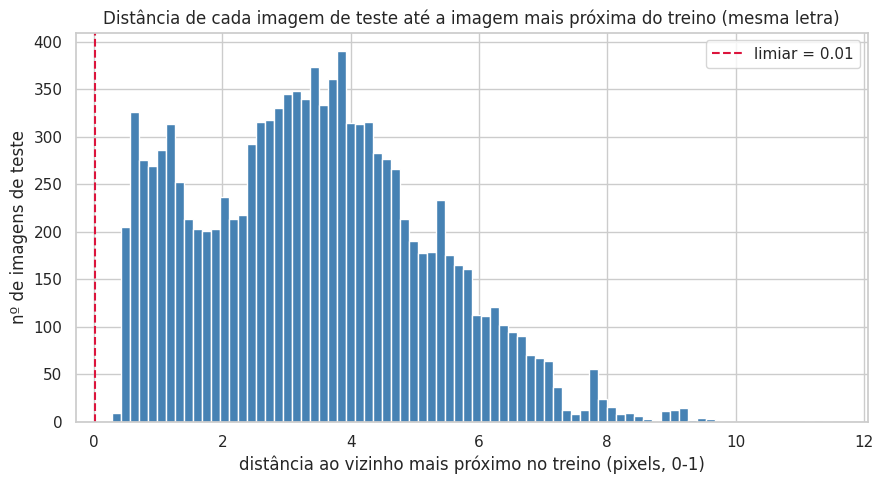

In [8]:
todas_distancias = np.concatenate(list(distancias_por_classe.values()))

fig, ax = plt.subplots(figsize=(9, 5))
ax.hist(todas_distancias, bins=80, color="steelblue")
ax.axvline(LIMIAR_QUASE_DUPLICATA, color="crimson", linestyle="--", label=f"limiar = {LIMIAR_QUASE_DUPLICATA}")
ax.set_xlabel("distância ao vizinho mais próximo no treino (pixels, 0-1)")
ax.set_ylabel("nº de imagens de teste")
ax.set_title("Distância de cada imagem de teste até a imagem mais próxima do treino (mesma letra)")
ax.legend()
plt.tight_layout()
plt.savefig("notebooks/leakage_alfabeto_histograma.png", dpi=120)
plt.show()

Achamos **33 imagens duplicadas (byte-a-byte) entre treino e teste, de um total de 11.548 imagens de teste (0,29%)**,
concentradas em só 3 das 21 classes (**A**: 15, **B**: 6, **C**: 12, as demais 18 letras não têm nenhuma duplicata).
Toda duplicata exata também apareceu como quase-duplicata (distância 0), ou seja, não existe um grupo maior de
"quase iguais mas não idênticas" escondido, o histograma mostra a maioria das distâncias bem longe do limiar,
com só esse pequeno pico em zero.

Diferente do leakage grave que achamos no `MINDS-Libras` (frames consecutivos do mesmo vídeo vazando entre
treino/teste, ~97% → ~49% de accuracy real), aqui o vazamento é mínimo e concentrado — não deveria inflar a métrica
de forma relevante. Mesmo assim, antes de reportar a accuracy final do classificador de letras, vale remover essas
33 imagens duplicadas do teste (ou tratar como treino) para que o número fique limpo, sem precisar refazer o split
inteiro como fizemos no dataset de palavras.

In [9]:
# Reexecuta a verificação após a limpeza, pra confirmar que não sobrou nenhuma duplicata
resultados_pos = []
for cls in CLASSES:
    arquivos_train = sorted((BASE / "train" / cls).glob("*.png"))
    arquivos_test = sorted((BASE / "test" / cls).glob("*.png"))
    hashes_train = {md5_arquivo(f) for f in arquivos_train}
    dup_exata = sum(1 for f in arquivos_test if md5_arquivo(f) in hashes_train)
    resultados_pos.append({"letra": cls, "n_test": len(arquivos_test), "duplicata_exata": dup_exata})

df_pos = pd.DataFrame(resultados_pos).set_index("letra")
print("Total de duplicatas restantes:", df_pos["duplicata_exata"].sum())
print("Total de imagens de teste agora:", df_pos["n_test"].sum())
df_pos[df_pos["duplicata_exata"] > 0]

Total de duplicatas restantes: 0
Total de imagens de teste agora: 11515


,n_test,duplicata_exata
letra,,


## Data Preparation (CRISP-DM)

Assim como no dataset de palavras, nao precisamos de:
- Imputacao de missing values: todas as pastas de classe tem imagens validas, nao ha arquivo faltante.
- Encoding de variaveis categoricas: a label e a propria pasta (letra), sera convertida com LabelEncoder so na hora do treino.
- Tratamento de outliers por IQR: nao faz sentido pra imagem, uma mao em angulo levemente diferente e sinal real, nao ruido.

O que ja fizemos de preparo real, documentado acima:
- Remocao de duplicatas entre treino e teste: as 33 imagens que apareciam identicas nos dois splits foram removidas do teste (secao de verificacao de leakage).

O que ainda falta decidir antes do treino: se o classificador vai usar os pixels da imagem diretamente (ex: CNN simples)
ou se vamos extrair landmarks de mao com MediaPipe Hands primeiro (mesma logica que usamos pro dataset de palavras com
pose, so que aqui precisa do `HandLandmarker` em vez do `PoseLandmarker`). Isso fica pra proxima etapa.